# 🧪 Forecasting Weekly Product Demand — Part 7: Improving the Model with Tracked Experiments

**Goal of this notebook:** try new features that target the two weaknesses found in Part 5, and track every experiment with **MLflow** so each result can be compared and reproduced.

**Weaknesses from Part 5:**
1. **Bulk orders:** one-off bulk-order weeks are only 3.9% of product-weeks but cause **28.5%** of the error. Part 6 showed that a few regular wholesale customers place very large orders.
2. **The gift-season peak is under-forecast:** bias is −18% on the test fold, worst for Christmas items.

**New features:**
- **Order features** (for weakness 1): how many orders a product gets per week and how big those orders are, built with SQL from the invoice lines (`sql/queries/weekly_orders.sql`).
- **Peak index** (for weakness 2): how strong each product's September–November season was over the last 52 weeks.

**Rules, so the result can be trusted:**
- Decisions are made on the **3 validation folds only**, exactly as in Parts 3–4.
- The model settings are the **tuned settings from Part 4**, unchanged, so only the features differ between experiments.
- The **test fold is used once**, for the chosen experiment only.

## 1. Setup and Data

The weekly units come from the same table as Parts 3–5. The new input is **orders per product per week** (number of distinct invoices), built in SQL with the same week rules as the weekly demand table, so the two tables line up row by row.

In [1]:
import sys
import logging
import warnings
warnings.filterwarnings("ignore")
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
import mlflow

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED_DIR = ROOT / "data" / "processed"

from src.db import RETAIL_DB, connect, run_query
from src.evaluation import evaluate
from src.features import (FEATURES, CATEGORICAL, HORIZON, PEAK_FEATURES, ORDER_FEATURES,
                          make_features, build_training_set, cap_outliers)

logging.getLogger("mlflow").setLevel(logging.ERROR)

bundle = joblib.load(ROOT / "models" / "forecast_bundle_v1.pkl")   # the Part 4 model
Y = bundle["history"]                    # week x product units (same as weekly_demand.parquet)
PARAMS = bundle["params"]                # tuned settings from Part 4
weeks = Y.index

with closing(connect(RETAIL_DB)) as conn:
    orders_long = run_query(conn, "weekly_orders")

O = orders_long.pivot(index="week", columns="stock_code", values="orders")
O.index = pd.to_datetime(O.index)
O = O[list(Y.columns)]
O.columns, O.index.name = Y.columns, Y.index.name

FOLD_ENDS = {"val 1": 71, "val 2": 79, "val 3": 87, "test": 95}
QUANTILES = {"p10": 0.1, "p50": 0.5, "p90": 0.9}

print(f"Units : {Y.shape}  Orders: {O.shape}")
print(f"Same weeks and products: {O.index.equals(Y.index) and O.columns.equals(Y.columns)}")
print(f"Weeks with no orders: {(O == 0).mean().mean():.1%}")

Units : (104, 100)  Orders: (104, 100)
Same weeks and products: True
Weeks with no orders: 5.9%


## 2. The New Features

All new features are built in `src/features.py`, next to the existing ones, and use **only weeks up to the forecast origin**.

| Feature | Meaning | Targets |
|---|---|---|
| `orders_ratio` | orders per week, last 4 weeks ÷ last 13 weeks | more or fewer buyers lately |
| `order_size_ratio` | units per order, last 4 weeks ÷ last 13 weeks | recent bulk orders |
| `log_units_per_order` | typical order size over 13 weeks (log) | wholesale-type products |
| `ly_peak_index` | average week in Sep–Nov ÷ average week, over the last 52 weeks | gift-season products |

Below: the values at the first validation origin, one row per product.

In [2]:
f = make_features(Y, FOLD_ENDS["val 1"], orders=O)
f[f["h"] == 1][PEAK_FEATURES + ORDER_FEATURES].describe().round(2)

,ly_peak_index,orders_ratio,order_size_ratio,log_units_per_order
count,100.00,100.00,100.00,100.00
mean,1.34,1.04,1.04,2.95
std,0.47,0.23,0.31,0.65
min,0.31,0.23,0.30,0.95
25%,1.05,0.96,0.87,2.51
50%,1.30,1.07,1.01,2.87
75%,1.55,1.16,1.16,3.31
max,3.11,1.58,2.27,5.15


📌 **Reading this:**
- `ly_peak_index` has a median of about **1.3**: a typical product sells about 30% more per week in September–November than in an average week, and some sell **2–3 times** more.
- `orders_ratio` and `order_size_ratio` sit around **1.0** (no change), with a spread in both directions, so they carry product-by-product signal.
- `log_units_per_order` separates products bought a few at a time from products bought in large wholesale quantities.

### 2.1 — Leakage check

The same check as in Part 4: put garbage into every week **after** the forecast origin, in both the units and the orders tables. If any feature changes, it is using future data.

In [3]:
origin = FOLD_ENDS["val 2"]
Y_fake, O_fake = Y.copy(), O.copy()
Y_fake.iloc[origin + 1:] = 999_999
O_fake.iloc[origin + 1:] = 999_999

pd.testing.assert_frame_equal(make_features(Y, origin, orders=O),
                              make_features(Y_fake, origin, orders=O_fake))
print("PASS - the new features do not use any data after the forecast origin")

PASS - the new features do not use any data after the forecast origin


## 3. Experiment Tracking with MLflow

Every experiment is one **MLflow run**. Each run stores:
- **parameters**: the model settings, the random seed, the list of features
- **metrics**: WAPE, Bias, MAE, MASE and p10–p90 coverage, per fold and averaged
- **tags**: the stage (`validation`, `seed check`, `test`, `final`)

The runs are saved in a local SQLite file (`mlflow.db`). They can be browsed in the MLflow web UI with:
```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("weekly-demand-features")

def qparams(alpha, seed):
    params = PARAMS | {"random_state": seed}
    return params if alpha == 0.5 else params | {"objective": "quantile", "alpha": alpha}

def fold_data(e):
    """Training rows and forecast rows for a fold whose last training week is e."""
    train_rows, fence = build_training_set(Y, e, orders=O)
    pred_rows = make_features(cap_outliers(Y.iloc[: e + 1], fence), e, orders=O)
    return train_rows, pred_rows

cache = {name: fold_data(e) for name, e in FOLD_ENDS.items() if name != "test"}

def fit_predict(train_rows, pred_rows, features, seed=42, quantiles=QUANTILES):
    """Train one model per quantile and return sorted forecasts (weeks x products)."""
    preds, models = [], {}
    for q, a in quantiles.items():
        m = lgb.LGBMRegressor(**qparams(a, seed))
        m.fit(train_rows[features], train_rows["y"],
              sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)
        p = m.predict(pred_rows[features]) * pred_rows["scale"].to_numpy()
        preds.append(np.clip(p, 0, None).reshape(HORIZON, -1))
        models[q] = m
    return dict(zip(quantiles, np.sort(np.stack(preds), axis=0))), models

def score(name, e, fc):
    actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
    r = evaluate(actual, fc["p50"], Y.iloc[: e + 1])
    if "p10" in fc:
        r["coverage"] = ((actual >= fc["p10"]) & (actual <= fc["p90"])).mean()
    return {"fold": name, **r}

def run_experiment(run_name, features, stage="validation", seed=42, quantiles=QUANTILES):
    """Train and score one feature set on the 3 validation folds, logged as one MLflow run."""
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tag("stage", stage)
        mlflow.log_params(qparams(0.5, seed))
        mlflow.log_param("n_features", len(features))
        mlflow.log_param("new_features", ", ".join(f for f in features if f not in FEATURES) or "none")
        mlflow.log_text("\n".join(features), "features.txt")

        rows = []
        for name, (train_rows, pred_rows) in cache.items():
            fc, _ = fit_predict(train_rows, pred_rows, features, seed, quantiles)
            r = score(name, FOLD_ENDS[name], fc)
            key = name.replace(" ", "")
            mlflow.log_metrics({f"{key}_WAPE": r["WAPE"], f"{key}_Bias": r["Bias"]})
            rows.append(r)

        res = pd.DataFrame(rows).set_index("fold")
        mean = res.drop(columns="bulk weeks").mean()
        mlflow.log_metrics({k.replace(" ", "_").replace("(", "").replace(")", ""): v
                            for k, v in mean.items()})
    return res

## 4. Experiments on the Validation Folds

Four runs, each with p10, p50 and p90 models on all three validation folds:
1. **baseline**: the Part 4 features (reproduces the Part 4 result)
2. **+ peak index**
3. **+ order features**
4. **+ peak + orders**

In [5]:
experiments = {
    "baseline": FEATURES,
    "+ peak index": FEATURES + PEAK_FEATURES,
    "+ order features": FEATURES + ORDER_FEATURES,
    "+ peak + orders": FEATURES + PEAK_FEATURES + ORDER_FEATURES,
}

val_results = {name: run_experiment(name, feats) for name, feats in experiments.items()}

print("WAPE per fold:")
print(pd.DataFrame({n: r["WAPE"] for n, r in val_results.items()}).T.round(4), "\n")

val_summary = pd.DataFrame({
    n: r[["MAE", "WAPE", "Bias", "MASE", "WAPE (no bulk weeks)", "coverage"]].mean()
    for n, r in val_results.items()
}).T
val_summary.round(4)

WAPE per fold:
fold               val 1   val 2   val 3
baseline          0.5406  0.5496  0.5262
+ peak index      0.5410  0.5533  0.5290
+ order features  0.5361  0.5443  0.5259
+ peak + orders   0.5356  0.5446  0.5294 



,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks),coverage
baseline,133.2884,0.5388,-0.1719,0.7369,0.5162,0.7921
+ peak index,133.8581,0.5411,-0.1729,0.7409,0.5186,0.7871
+ order features,132.4803,0.5354,-0.1770,0.7329,0.5127,0.7875
+ peak + orders,132.7739,0.5365,-0.1772,0.7354,0.5138,0.7862


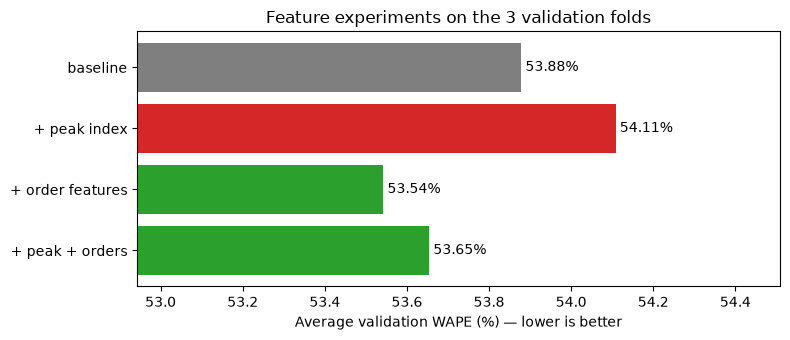

In [6]:
wape = val_summary["WAPE"] * 100
colors = ["tab:grey"] + ["tab:green" if v < wape["baseline"] else "tab:red" for v in wape.iloc[1:]]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(wape.index, wape, color=colors)
ax.invert_yaxis()
for i, v in enumerate(wape):
    ax.text(v, i, f" {v:.2f}%", va="center")
ax.set_xlim(wape.min() - 0.6, wape.max() + 0.4)
ax.set_xlabel("Average validation WAPE (%) — lower is better")
ax.set_title("Feature experiments on the 3 validation folds")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The **baseline reproduces Part 4 exactly** (53.88% validation WAPE), so the comparison is fair.
- **Order features help**: WAPE drops to **53.54%**, with lower MAE, MASE and bulk-free WAPE. They are better on val 1 and val 2 and equal on val 3.
- **The peak index makes things slightly worse** (54.11%). This is not surprising: none of the validation folds contains the gift season (they forecast April to early October), so a gift-season feature has nothing to improve there and only adds noise.
- Using both is worse than order features alone.

The gain from order features is small (about 0.3 percentage points), so before choosing it we check that it is not just luck.

## 5. Is the Gain Real? Five Random Seeds

LightGBM uses random row and column sampling, so a different random seed gives a slightly different model. If the gain from order features were luck, it would disappear or flip with other seeds. We repeat the comparison with **5 seeds × 3 folds = 15 pairs** (p50 models only, which is what WAPE measures).

In [7]:
seed_rows = []
for seed in [42, 1, 2, 3, 4]:
    for name in ["baseline", "+ order features"]:
        res = run_experiment(f"{name} (seed {seed})", experiments[name], stage="seed check",
                             seed=seed, quantiles={"p50": 0.5})
        for fold, w in res["WAPE"].items():
            seed_rows.append({"seed": seed, "experiment": name, "fold": fold, "WAPE": w})

seeds = pd.DataFrame(seed_rows).pivot_table(index=["seed", "fold"], columns="experiment", values="WAPE")
seeds["difference"] = seeds["+ order features"] - seeds["baseline"]

print(f"Order features better in {(seeds['difference'] < 0).sum()} of {len(seeds)} seed-fold pairs")
print(f"Average difference: {seeds['difference'].mean() * 100:+.2f} percentage points")
seeds.round(4)

Order features better in 13 of 15 seed-fold pairs
Average difference: -0.29 percentage points


experiment  + order features  baseline  difference
seed fold                                         
1    val 1            0.5354    0.5399     -0.0044
     val 2            0.5454    0.5492     -0.0038
     val 3            0.5259    0.5256      0.0003
2    val 1            0.5344    0.5364     -0.0020
     val 2            0.5447    0.5496     -0.0050
     val 3            0.5261    0.5263     -0.0002
3    val 1            0.5390    0.5406     -0.0017
     val 2            0.5460    0.5505     -0.0045
     val 3            0.5248    0.5254     -0.0006
4    val 1            0.5355    0.5424     -0.0068
     val 2            0.5443    0.5493     -0.0050
     val 3            0.5261    0.5257      0.0004
42   val 1            0.5361    0.5406     -0.0045
     val 2            0.5443    0.5496     -0.0053
     val 3            0.5259    0.5262     -0.0003

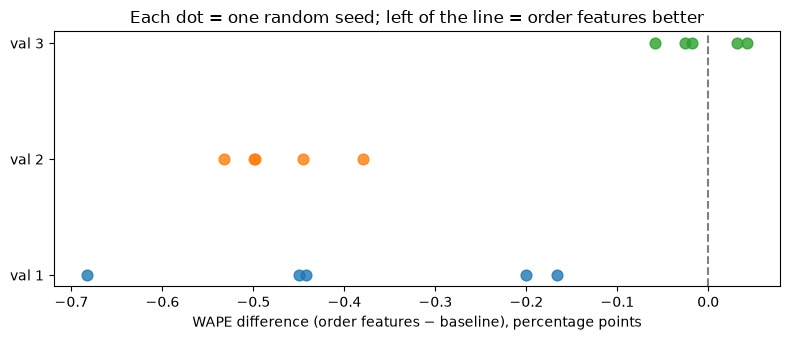

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for fold, color in zip(["val 1", "val 2", "val 3"], ["tab:blue", "tab:orange", "tab:green"]):
    d = seeds.xs(fold, level="fold")["difference"] * 100
    ax.scatter(d, [fold] * len(d), color=color, s=60, alpha=0.8)
ax.axvline(0, color="grey", linestyle="--")
ax.set_xlabel("WAPE difference (order features − baseline), percentage points")
ax.set_title("Each dot = one random seed; left of the line = order features better")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- Order features are better in **13 of 15** seed-fold pairs, by about **0.3 percentage points** on average.
- On **val 1 and val 2 they win with every seed**. On val 3 the two are equal (differences of ±0.06 points are noise).
- So the gain is small but **consistent**, not luck.

**Decision (made on validation only):** use the **Part 4 features + order features**. The peak index is not used.

## 6. The Test Fold — Used Once

The chosen feature set is now trained on all weeks before the test fold (10 Oct – 28 Nov 2011, the run-up to Christmas) and scored once, next to the Part 4 model trained the same way.

In [9]:
e = FOLD_ENDS["test"]
train_rows, pred_rows = fold_data(e)
actual = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()

test_fc, test_rows = {}, []
for name in ["baseline", "+ order features"]:
    stage = "test"
    with mlflow.start_run(run_name=f"{name} (test)"):
        mlflow.set_tag("stage", stage)
        mlflow.log_param("new_features", ", ".join(f for f in experiments[name] if f not in FEATURES) or "none")
        fc, models = fit_predict(train_rows, pred_rows, experiments[name])
        r = score("test", e, fc)
        mlflow.log_metrics({k.replace(" ", "_").replace("(", "").replace(")", ""): v
                            for k, v in r.items() if k != "fold"})
    test_fc[name] = fc
    test_rows.append({"model": name, **{k: v for k, v in r.items() if k != "fold"}})
    if name == "+ order features":
        test_models = models

test_results = pd.DataFrame(test_rows).set_index("model")
test_results[["MAE", "WAPE", "Bias", "MASE", "WAPE (no bulk weeks)", "coverage"]].round(4)

,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks),coverage
model,,,,,,
baseline,160.1787,0.5342,-0.1827,0.9253,0.4753,0.8175
+ order features,158.5439,0.5288,-0.1861,0.9181,0.4690,0.8150


📌 **Reading this:** On the test fold the new model is better on the main metrics:
- **WAPE 53.4% → 52.9%** and **MAE 160.2 → 158.5** units per product-week.
- WAPE without bulk weeks improves as well (47.5% → 46.9%), and MASE goes down (0.925 → 0.918).
- p10–p90 coverage stays close to the 80% target (81.5%).

The gain is about the same size as on validation, which is what we expect when the choice was made honestly.

### 6.1 — Did it fix the Christmas under-forecast?

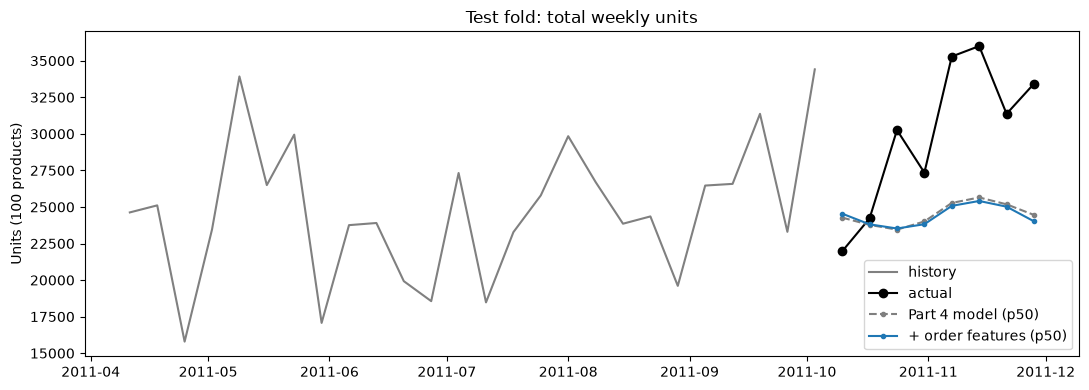

Bias  Part 4 model: -18.3%   + order features: -18.6%


In [10]:
test_weeks = weeks[e + 1 : e + 1 + HORIZON]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weeks[e - 25 : e + 1], Y.iloc[e - 25 : e + 1].sum(axis=1), color="grey", label="history")
ax.plot(test_weeks, actual.sum(axis=1), color="black", marker="o", label="actual")
ax.plot(test_weeks, test_fc["baseline"]["p50"].sum(axis=1), color="tab:grey", linestyle="--",
        marker=".", label="Part 4 model (p50)")
ax.plot(test_weeks, test_fc["+ order features"]["p50"].sum(axis=1), color="tab:blue",
        marker=".", label="+ order features (p50)")
ax.set_ylabel("Units (100 products)")
ax.set_title("Test fold: total weekly units")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Bias  Part 4 model: {test_results.loc['baseline', 'Bias']:+.1%}   "
      f"+ order features: {test_results.loc['+ order features', 'Bias']:+.1%}")

📌 **Reading this:** **No.** Both models follow almost the same line and stay well below the actual November peak. Bias is about **−18.6%**, practically unchanged. The order features reduce errors from bulk orders and recent changes in buying, which is where the WAPE gain comes from, but they do not tell the model how much bigger the 2011 peak would be.

Why the peak is hard: the model only sees **one earlier gift season** (2010), and the 2010 peak weeks have no "last year" values, because the data starts in December 2009. A tree model cannot predict values larger than anything it learned from, so it under-forecasts the peak. This stays the main limitation, which is why the app recommends stocking to **p90**.

### 6.2 — How much does the model use the new features?

In [11]:
features = experiments["+ order features"]
importance = pd.Series(test_models["p50"].booster_.feature_importance("gain"), index=features)
importance = (importance / importance.sum() * 100).sort_values(ascending=False)

rank = {f: int(importance.index.get_loc(f)) + 1 for f in ORDER_FEATURES}
print("Rank of the new features (out of", len(features), "):", rank)
importance.round(1).head(10)

Rank of the new features (out of 23 ): {'orders_ratio': 6, 'order_size_ratio': 20, 'log_units_per_order': 10}


product                23.0
week_of_year           17.9
ly_smooth              15.1
weeks_to_xmas          12.2
n_holidays              9.2
orders_ratio            6.0
ly_same                 4.3
log_scale               3.7
month                   2.2
log_units_per_order     1.5
dtype: float64

📌 **Reading this:** The table shows each feature's share of the model's total **gain** (how much it reduced the training error).
- `orders_ratio` is the **6th most used feature out of 23** (about 6% of the gain), more than last year's same-week value (`ly_same`). A change in how many customers are buying a product is a useful early signal.
- `log_units_per_order` ranks 10th. `order_size_ratio` is barely used (20th): once the other features are in, the recent change in order size adds little.
- The product identity and the yearly-season features (`week_of_year`, `ly_smooth`, `weeks_to_xmas`) still do most of the work, which fits a small but steady improvement.

## 7. Save the Candidate Model to MLflow

The chosen feature set is retrained on **all 104 weeks** (as in Part 4), and the three quantile models are saved in MLflow. The p50 model is also added to the **MLflow Model Registry** as `weekly-demand-p50`, so each saved version has a number and can be compared or rolled back.

In [12]:
LAST = len(weeks) - 1
train_all, fence_all = build_training_set(Y, LAST, orders=O)
features = experiments["+ order features"]

with mlflow.start_run(run_name="+ order features (final, all weeks)"):
    mlflow.set_tag("stage", "final")
    mlflow.log_params(qparams(0.5, 42))
    mlflow.log_param("new_features", ", ".join(ORDER_FEATURES))
    mlflow.log_text("\n".join(features), "features.txt")
    mlflow.log_metrics({"test_WAPE": test_results.loc["+ order features", "WAPE"],
                        "test_Bias": test_results.loc["+ order features", "Bias"],
                        "test_coverage": test_results.loc["+ order features", "coverage"]})
    final_models = {}
    for q, a in QUANTILES.items():
        m = lgb.LGBMRegressor(**qparams(a, 42))
        m.fit(train_all[features], train_all["y"],
              sample_weight=train_all["scale"], categorical_feature=CATEGORICAL)
        final_models[q] = m
        mlflow.lightgbm.log_model(
            m, name=f"model_{q}",
            registered_model_name="weekly-demand-p50" if q == "p50" else None,
        )

print(f"Trained on {len(train_all):,} rows, up to {weeks[LAST]:%d %b %Y}")

Successfully registered model 'weekly-demand-p50'.
Created version '1' of model 'weekly-demand-p50'.


Trained on 70,000 rows, up to 28 Nov 2011


## 8. Save the New Model for the App

The app loads one file, `models/forecast_bundle.pkl` (see Part 4). The new bundle has the same keys, plus the **weekly order counts**, which the order features need. The Part 4 model stays available as `models/forecast_bundle_v1.pkl`, so Parts 4 and 5 can still be re-run.

After saving, `python scripts/build_db.py` copies the units, orders and test metrics into `data/app.db`, which the app reads with SQL.

In [13]:
test_new = test_results.loc["+ order features"]
bundle_v2 = {
    "models": final_models,
    "quantiles": QUANTILES,
    "params": PARAMS,
    "features": features,
    "categorical": CATEGORICAL,
    "horizon": HORIZON,
    "fence": fence_all,
    "history": Y,
    "orders": O,
    "product_names": bundle["product_names"],
    "trained_until": str(weeks[LAST].date()),
    "test_metrics": {
        "test_period": bundle["test_metrics"]["test_period"],
        "WAPE": round(float(test_new["WAPE"]), 3),
        "WAPE_baseline_ma13": bundle["test_metrics"]["WAPE_baseline_ma13"],
        "Bias": round(float(test_new["Bias"]), 3),
        "coverage_p10_p90": round(float(test_new["coverage"]), 3),
    },
}
joblib.dump(bundle_v2, ROOT / "models" / "forecast_bundle.pkl")

# check: the saved file gives the same forecasts as the models in memory
from src.forecast import forecast
loaded = joblib.load(ROOT / "models" / "forecast_bundle.pkl")
fc_saved = forecast(loaded)
print(f"Saved models/forecast_bundle.pkl ({(ROOT / 'models' / 'forecast_bundle.pkl').stat().st_size / 1e6:.2f} MB)")
print(f"Features: {len(loaded['features'])}  |  test metrics: {loaded['test_metrics']}")
print(f"Forecast rows: {len(fc_saved)}  ({fc_saved['StockCode'].nunique()} products x {fc_saved['h'].nunique()} weeks)")

Saved models/forecast_bundle.pkl (1.52 MB)
Features: 23  |  test metrics: {'test_period': '2011-10-10 to 2011-11-28', 'WAPE': 0.529, 'WAPE_baseline_ma13': 0.579, 'Bias': -0.186, 'coverage_p10_p90': 0.815}
Forecast rows: 800  (100 products x 8 weeks)


## 9. All Runs in One Table

Everything logged above, read back from MLflow. The same table is saved to `data/processed/feature_experiments.csv`, so the results can be read on GitHub without running MLflow.

In [14]:
runs = mlflow.search_runs(experiment_names=["weekly-demand-features"], order_by=["attributes.start_time ASC"])
cols = {"tags.mlflow.runName": "run", "tags.stage": "stage", "params.new_features": "new features",
        "metrics.WAPE": "WAPE", "metrics.Bias": "Bias", "metrics.MAE": "MAE",
        "metrics.coverage": "coverage", "metrics.test_WAPE": "final: test WAPE"}
table = runs[list(cols)].rename(columns=cols)
table.to_csv(PROCESSED_DIR / "feature_experiments.csv", index=False)

print(f"{len(table)} runs logged")
table.round(4)

17 runs logged


,run,stage,new features,WAPE,Bias,MAE,coverage,final: test WAPE
0,baseline,validation,none,0.5388,-0.1719,133.2884,0.7921,NaN
1,+ peak index,validation,ly_peak_index,0.5411,-0.1729,133.8581,0.7871,NaN
2,+ order features,validation,"orders_ratio, order_size_ratio, log_units_per_...",0.5354,-0.1770,132.4803,0.7875,NaN
3,+ peak + orders,validation,"ly_peak_index, orders_ratio, order_size_ratio,...",0.5365,-0.1772,132.7739,0.7862,NaN
4,baseline (seed 42),seed check,none,0.5388,-0.1719,133.2884,NaN,NaN
5,+ order features (seed 42),seed check,"orders_ratio, order_size_ratio, log_units_per_...",0.5354,-0.1770,132.4803,NaN,NaN
6,baseline (seed 1),seed check,none,0.5382,-0.1725,133.1445,NaN,NaN
7,+ order features (seed 1),seed check,"orders_ratio, order_size_ratio, log_units_per_...",0.5356,-0.1772,132.5134,NaN,NaN
8,baseline (seed 2),seed check,none,0.5374,-0.1677,132.9606,NaN,NaN
9,+ order features (seed 2),seed check,"orders_ratio, order_size_ratio, log_units_per_...",0.5350,-0.1765,132.3883,NaN,NaN


## 10. Summary

**What was tried**
- Four new features, aimed at the two weaknesses from Part 5: three **order features** built with SQL (orders per week, order size), and a **peak index** for gift-season products.
- Every run was tracked in **MLflow** (parameters, features, metrics per fold), and the final models were saved in the MLflow Model Registry.
- The improved model is saved as `models/forecast_bundle.pkl` and is now the model the app uses; its weekly order counts reach the app through `data/app.db`.

**What worked**
- **Order features** lowered validation WAPE from 53.88% to 53.54%, and the gain held in 13 of 15 random-seed checks.
- On the test fold, used once: **WAPE 53.4% → 52.9%**, MAE 160.2 → 158.5, coverage still ~81%.

**What did not work, and why**
- The **peak index** did not help on validation, because no validation fold contains a gift season.
- The **Christmas under-forecast is not fixed** (bias about −18.6%). With only one earlier gift season and no "last year" values for it, the model cannot learn how big a peak can get. More years of history are the real fix.

**Next steps**
- With more data: a validation fold inside a gift season, so peak features can be tested properly.
- Combine the model with a seasonal multiplier for gift-season weeks, since tree models cannot extrapolate above what they have seen.